Cell 1 – Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    silhouette_score
)

import warnings
warnings.filterwarnings('ignore')

Cell 2 – Upload dataset

In [2]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv('Social_Network_Ads.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (400, 5)


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


Cell 3 – Understand the dataset

In [3]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nPurchase Distribution:")
print(df['Purchased'].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB

Statistical Summary:


,User ID,Age,EstimatedSalary,Purchased
count,4.000000e+02,400.000000,400.000000,400.000000
mean,1.569154e+07,37.655000,69742.500000,0.357500
std,7.165832e+04,10.482877,34096.960282,0.479864
min,1.556669e+07,18.000000,15000.000000,0.000000
25%,1.562676e+07,29.750000,43000.000000,0.000000
50%,1.569434e+07,37.000000,70000.000000,0.000000
75%,1.575036e+07,46.000000,88000.000000,1.000000
max,1.581524e+07,60.000000,150000.000000,1.000000



Missing Values:
User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

Duplicate Records:
0

Purchase Distribution:
Purchased
0    257
1    143
Name: count, dtype: int64


Cell 4 – Exploratory Data Analysis

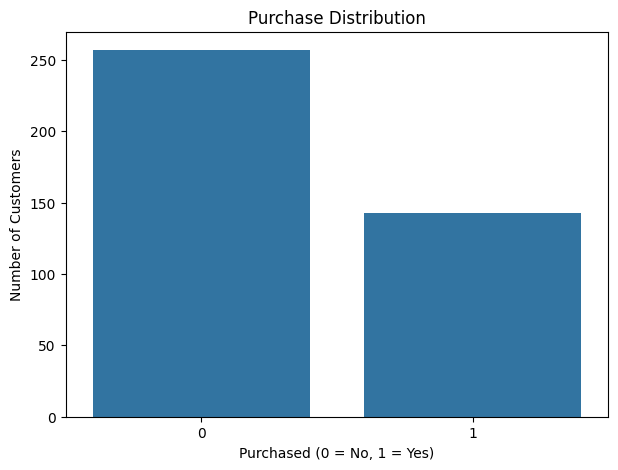

In [4]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x='Purchased')

plt.title('Purchase Distribution')
plt.xlabel('Purchased (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')

plt.show()

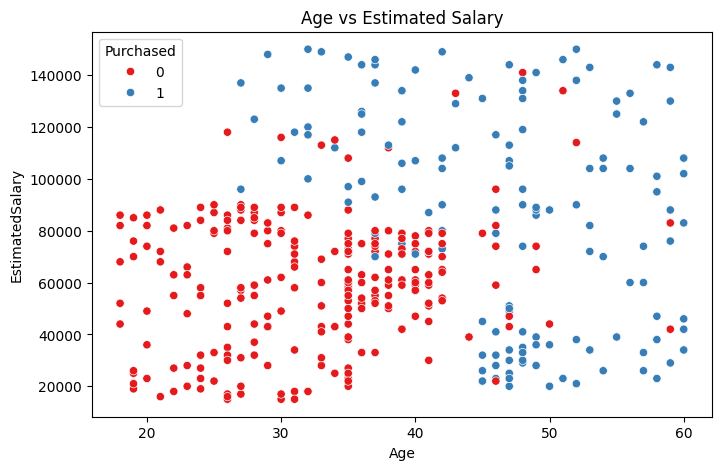

In [5]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='Age',
    y='EstimatedSalary',
    hue='Purchased',
    palette='Set1'
)

plt.title('Age vs Estimated Salary')
plt.show()

Cell 5 – Feature selection

In [6]:
X = df[['Age', 'EstimatedSalary']]

y = df['Purchased']

print("Input Features:")
display(X.head())

print("\nTarget:")
print(y.head())

Input Features:


,Age,EstimatedSalary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000



Target:
0    0
1    0
2    0
3    0
4    0
Name: Purchased, dtype: int64


Cell 6 – Split training and testing data

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (300, 2)
Testing data: (100, 2)


Cell 7 – Feature scaling and KNN model

In [8]:
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

knn_pipeline.fit(X_train, y_train)

print("KNN Model trained successfully!")

KNN Model trained successfully!


Cell 8 – Predict results

In [9]:
y_pred = knn_pipeline.predict(X_test)

results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

display(results.head(15))

,Actual,Predicted
0,1,0
1,0,0
2,1,0
3,0,0
4,1,1
5,0,0
6,0,0
7,0,0
8,1,1
9,0,0


Cell 9 – Evaluate model performance

In [10]:
accuracy = accuracy_score(y_test, y_pred)

print("KNN Model Accuracy:",
      round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

KNN Model Accuracy: 91.0 %

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.94      0.93        64
           1       0.89      0.86      0.87        36

    accuracy                           0.91       100
   macro avg       0.90      0.90      0.90       100
weighted avg       0.91      0.91      0.91       100



Cell 10 – Confusion matrix

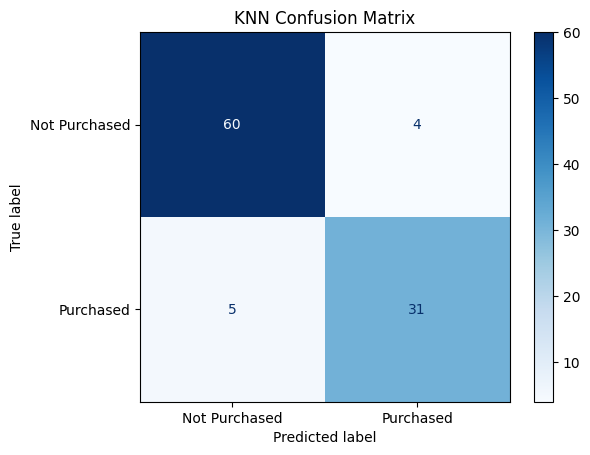

In [11]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Purchased', 'Purchased']
)

disp.plot(cmap='Blues')

plt.title('KNN Confusion Matrix')
plt.show()

Cell 11 – Find the best K value

In [12]:
param_grid = {
    'knn__n_neighbors': range(1, 21)
}

grid = GridSearchCV(
    knn_pipeline,
    param_grid,
    cv=5,
    scoring='accuracy'
)

grid.fit(X_train, y_train)

print("Best K Value:", grid.best_params_)
print("Best Cross Validation Accuracy:",
      round(grid.best_score_ * 100, 2), "%")

best_knn = grid.best_estimator_

best_predictions = best_knn.predict(X_test)

print("Test Accuracy:",
      round(accuracy_score(y_test, best_predictions) * 100, 2), "%")

Best K Value: {'knn__n_neighbors': 9}
Best Cross Validation Accuracy: 91.33 %
Test Accuracy: 92.0 %


Cell 12 – Test with a new customer

In [13]:
new_customer = pd.DataFrame({
    'Age': [35],
    'EstimatedSalary': [60000]
})

prediction = best_knn.predict(new_customer)

if prediction[0] == 1:
    print("Prediction: Customer is likely to purchase.")
else:
    print("Prediction: Customer is unlikely to purchase.")

Prediction: Customer is unlikely to purchase.


Cell 13 – Save prediction results

In [14]:
df_results = X_test.copy()

df_results['Actual Purchase'] = y_test
df_results['Predicted Purchase'] = best_predictions

df_results.to_csv(
    'KNN_Customer_Purchase_Predictions.csv',
    index=False
)

print("Results saved successfully!")

Results saved successfully!
